# End-to-End ML System for Business Intelligence
## 1. Business Problem
A telecom company loses revenue when customers churn.

## 2. Objective
Predict churners, find the reasons, and recommend retention actions.

## 3. Dataset
Telco Customer Churn (Kaggle), ___ rows, ___ columns. Target: Churn (Yes/No).

## 4. Tools
Python, NumPy, Pandas, Matplotlib, Seaborn, Scikit-learn, Jupyter


In [1]:

%pip install seaborn scikit-learn


     ---------------------------------------- 0.0/60.8 kB ? eta -:--:--
     --------------------------------- ------ 51.2/60.8 kB ? eta -:--:--
     -------------------------------------- 60.8/60.8 kB 538.3 kB/s eta 0:00:00
   ---------------------------------------- 0.0/12.6 MB ? eta -:--:--
    --------------------------------------- 0.2/12.6 MB 3.9 MB/s eta 0:00:04
   - -------------------------------------- 0.5/12.6 MB 4.9 MB/s eta 0:00:03
   --- ------------------------------------ 1.0/12.6 MB 7.2 MB/s eta 0:00:02
   ---- ----------------------------------- 1.4/12.6 MB 7.8 MB/s eta 0:00:02
   ---- ----------------------------------- 1.5/12.6 MB 6.4 MB/s eta 0:00:02
   ----- ---------------------------------- 1.7/12.6 MB 6.9 MB/s eta 0:00:02
   ------- -------------------------------- 2.3/12.6 MB 7.2 MB/s eta 0:00:02
   ----------- ---------------------------- 3.5/12.6 MB 9.3 MB/s eta 0:00:01
   ------------ --------------------------- 4.0/12.6 MB 9.4 MB/s eta 0:00:01
   ---------

ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
streamlit 1.35.0 requires numpy<2,>=1.19.3, but you have numpy 2.2.6 which is incompatible.
streamlit 1.35.0 requires protobuf<5,>=3.20, but you have protobuf 5.27.3 which is incompatible.
tensorflow-intel 2.16.2 requires numpy<2.0.0,>=1.26.0; python_version >= "3.12", but you have numpy 2.2.6 which is incompatible.
tensorflow-intel 2.16.2 requires protobuf!=4.21.0,!=4.21.1,!=4.21.2,!=4.21.3,!=4.21.4,!=4.21.5,<5.0.0dev,>=3.20.3, but you have protobuf 5.27.3 which is incompatible.

[notice] A new release of pip is available: 24.0 -> 26.2.1
[notice] To update, run: python.exe -m pip install --upgrade pip


In [2]:

import pandas as pd, numpy as np
import matplotlib.pyplot as plt, seaborn as sns
import warnings
warnings.filterwarnings("ignore")
print("Ready")

Ready


In [3]:
df = pd.read_csv("WA_Fn-UseC_-Telco-Customer-Churn.csv")
print(df.shape)
df.head()

(7043, 21)


,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,...,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


In [4]:
df.info()
print(df.isnull().sum().sum())

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 21 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   customerID        7043 non-null   object 
 1   gender            7043 non-null   object 
 2   SeniorCitizen     7043 non-null   int64  
 3   Partner           7043 non-null   object 
 4   Dependents        7043 non-null   object 
 5   tenure            7043 non-null   int64  
 6   PhoneService      7043 non-null   object 
 7   MultipleLines     7043 non-null   object 
 8   InternetService   7043 non-null   object 
 9   OnlineSecurity    7043 non-null   object 
 10  OnlineBackup      7043 non-null   object 
 11  DeviceProtection  7043 non-null   object 
 12  TechSupport       7043 non-null   object 
 13  StreamingTV       7043 non-null   object 
 14  StreamingMovies   7043 non-null   object 
 15  Contract          7043 non-null   object 
 16  PaperlessBilling  7043 non-null   object 


In [5]:
df = df.drop("customerID", axis=1)
df["TotalCharges"] = pd.to_numeric(df["TotalCharges"], errors="coerce")
print(df["TotalCharges"].isnull().sum())
df = df.dropna()
df["Churn"] = df["Churn"].map({"Yes": 1, "No": 0})
print(df.shape)

11
(7032, 20)


Churn
0    0.734215
1    0.265785
Name: proportion, dtype: float64


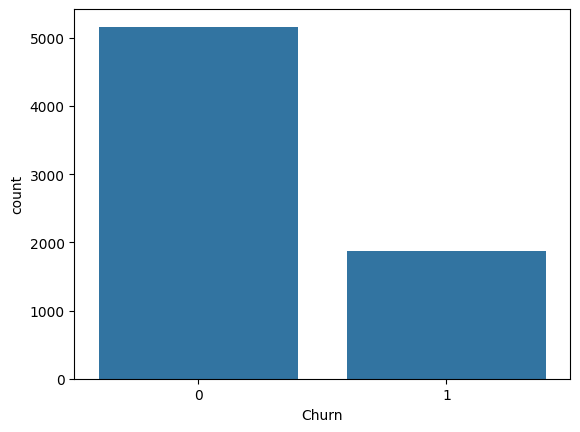

In [6]:
print(df["Churn"].value_counts(normalize=True))
sns.countplot(x="Churn", data=df)
plt.show()

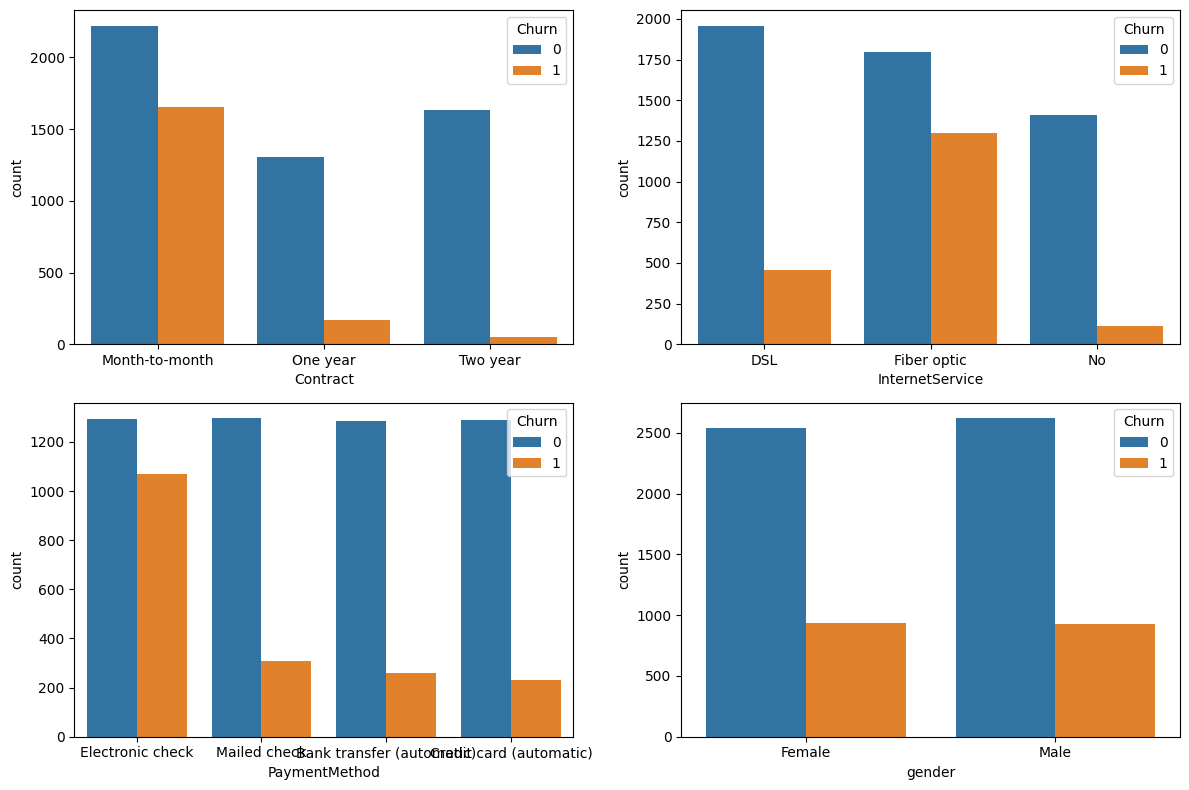

In [7]:
cols = ["Contract", "InternetService", "PaymentMethod", "gender"]
fig, axes = plt.subplots(2, 2, figsize=(12, 8))
for ax, c in zip(axes.flatten(), cols):
    sns.countplot(x=c, hue="Churn", data=df, ax=ax)
plt.tight_layout()
plt.show()

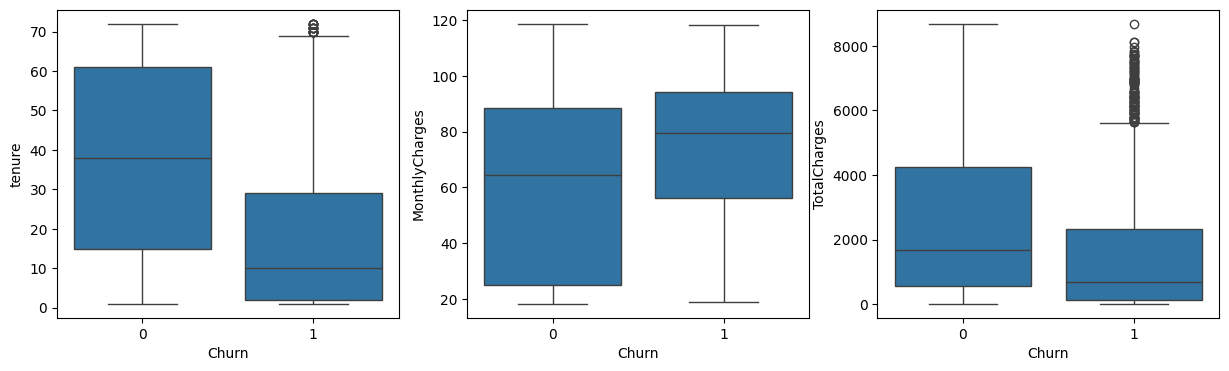

In [8]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for ax, c in zip(axes, ["tenure", "MonthlyCharges", "TotalCharges"]):
    sns.boxplot(x="Churn", y=c, data=df, ax=ax)
plt.show()

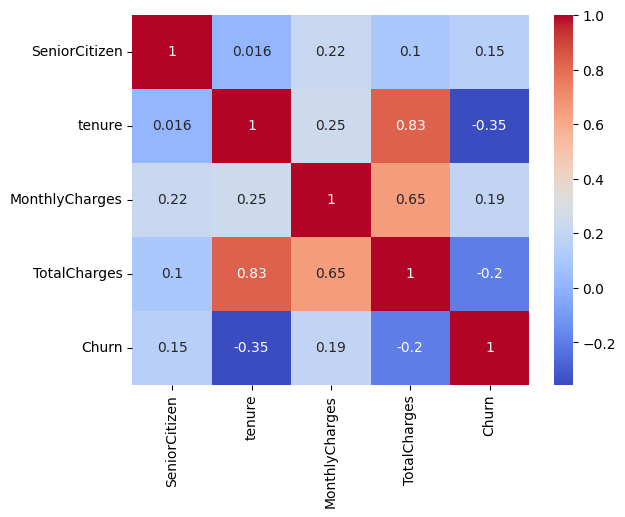

In [9]:
sns.heatmap(df.corr(numeric_only=True), annot=True, cmap="coolwarm")
plt.show()

## 5. Pipeline
- Data cleaning: dropped customerID, fixed TotalCharges, removed ___ null rows
- EDA: churn rate ___%, charts by contract, tenure, charges
- Feature engineering: TenureGroup, AvgMonthlySpend, NumServices
- Encoding: get_dummies; Scaling: StandardScaler
- Split: 80/20, stratified

In [10]:
df["TenureGroup"] = pd.cut(df["tenure"], bins=[0, 12, 24, 48, 72], labels=["0-1yr", "1-2yr", "2-4yr", "4-6yr"])
df["AvgMonthlySpend"] = df["TotalCharges"] / df["tenure"]
services = ["PhoneService", "OnlineSecurity", "OnlineBackup", "DeviceProtection", "TechSupport", "StreamingTV", "StreamingMovies"]
df["NumServices"] = (df[services] == "Yes").sum(axis=1)
df[["TenureGroup", "AvgMonthlySpend", "NumServices"]].head()

,TenureGroup,AvgMonthlySpend,NumServices
0,0-1yr,29.850000,1
1,2-4yr,55.573529,3
2,0-1yr,54.075000,3
3,2-4yr,40.905556,3
4,0-1yr,75.825000,1


In [11]:
df_model = pd.get_dummies(df, drop_first=True, dtype=int)
X = df_model.drop("Churn", axis=1)
y = df_model["Churn"]
print(X.shape)

(7032, 35)


In [12]:
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)

scaler = StandardScaler()
X_train_s = scaler.fit_transform(X_train)
X_test_s = scaler.transform(X_test)
print(X_train.shape, X_test.shape)

(5625, 35) (1407, 35)


In [13]:
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier
from sklearn.metrics import accuracy_score, recall_score, precision_score, f1_score

models = {
    "Logistic Regression": LogisticRegression(max_iter=1000),
    "Random Forest": RandomForestClassifier(random_state=42),
    "Gradient Boosting": GradientBoostingClassifier(random_state=42),
}

results = []
for name, m in models.items():
    if name == "Logistic Regression":
        m.fit(X_train_s, y_train)
        pred = m.predict(X_test_s)
    else:
        m.fit(X_train, y_train)
        pred = m.predict(X_test)
    results.append({
        "Model": name,
        "Accuracy": accuracy_score(y_test, pred),
        "Precision": precision_score(y_test, pred),
        "Recall": recall_score(y_test, pred),
        "F1": f1_score(y_test, pred),
    })

In [14]:
results_df = pd.DataFrame(results).round(3)
results_df

,Model,Accuracy,Precision,Recall,F1
0,Logistic Regression,0.793,0.633,0.527,0.575
1,Random Forest,0.784,0.617,0.492,0.548
2,Gradient Boosting,0.797,0.646,0.527,0.580


In [15]:
lr_bal = LogisticRegression(max_iter=1000, class_weight="balanced")
rf_bal = RandomForestClassifier(random_state=42, class_weight="balanced")
lr_bal.fit(X_train_s, y_train)
rf_bal.fit(X_train, y_train)

bal_results = []
for name, m, Xt in [("LogReg (balanced)", lr_bal, X_test_s), ("RandomForest (balanced)", rf_bal, X_test)]:
    pred = m.predict(Xt)
    bal_results.append({
        "Model": name,
        "Accuracy": accuracy_score(y_test, pred),
        "Precision": precision_score(y_test, pred),
        "Recall": recall_score(y_test, pred),
        "F1": f1_score(y_test, pred),
    })

all_results = pd.concat([results_df, pd.DataFrame(bal_results).round(3)], ignore_index=True)
all_results

,Model,Accuracy,Precision,Recall,F1
0,Logistic Regression,0.793,0.633,0.527,0.575
1,Random Forest,0.784,0.617,0.492,0.548
2,Gradient Boosting,0.797,0.646,0.527,0.580
3,LogReg (balanced),0.721,0.485,0.791,0.602
4,RandomForest (balanced),0.784,0.622,0.479,0.541


## 6. Model Comparison
Trained Logistic Regression, Random Forest, Gradient Boosting, plus balanced versions.
Best model: ___ (Accuracy ___, Recall ___)
Reason: recall is prioritised because a missed churner costs revenue.

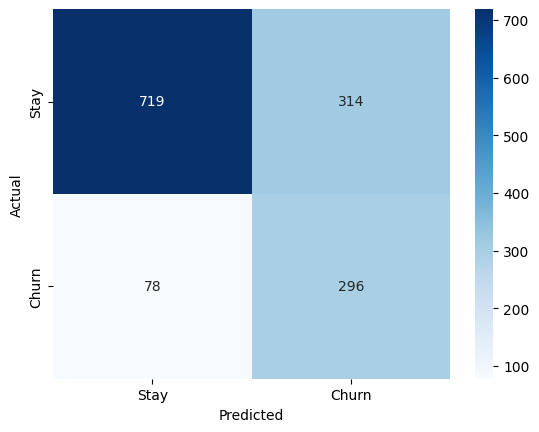

              precision    recall  f1-score   support

           0       0.90      0.70      0.79      1033
           1       0.49      0.79      0.60       374

    accuracy                           0.72      1407
   macro avg       0.69      0.74      0.69      1407
weighted avg       0.79      0.72      0.74      1407



In [16]:
from sklearn.metrics import confusion_matrix, classification_report
best_pred = lr_bal.predict(X_test_s)
sns.heatmap(confusion_matrix(y_test, best_pred), annot=True, fmt="d", cmap="Blues",
            xticklabels=["Stay", "Churn"], yticklabels=["Stay", "Churn"])
plt.xlabel("Predicted"); plt.ylabel("Actual")
plt.show()
print(classification_report(y_test, best_pred))

In [17]:
risk = lr_bal.predict_proba(X_test_s)[:, 1]

report = df.loc[X_test.index, ["Contract", "tenure", "MonthlyCharges"]].copy()
report["Actual"] = y_test.values
report["RiskScore"] = risk.round(3)
report["RiskLevel"] = pd.cut(risk, bins=[0, 0.4, 0.7, 1], labels=["Low", "Medium", "High"])

print(report["RiskLevel"].value_counts())
report.sort_values("RiskScore", ascending=False).head(10)

RiskLevel
Low       677
Medium    366
High      364
Name: count, dtype: int64


,Contract,tenure,MonthlyCharges,Actual,RiskScore,RiskLevel
3159,Month-to-month,3,94.85,0,0.950,High
3380,Month-to-month,1,95.10,1,0.950,High
2631,Month-to-month,7,99.25,1,0.943,High
2797,Month-to-month,3,100.95,1,0.939,High
4585,Month-to-month,1,85.05,1,0.938,High
582,Month-to-month,4,89.20,1,0.937,High
3727,Month-to-month,3,96.60,1,0.936,High
933,Month-to-month,4,84.60,1,0.933,High
6240,Month-to-month,1,93.30,1,0.931,High
6574,Month-to-month,9,90.10,0,0.925,High


In [18]:
coef = pd.Series(lr_bal.coef_[0], index=X.columns).sort_values()
print("Reduce churn (negative):\n", coef.head(5))
print("\nIncrease churn (positive):\n", coef.tail(5))

Reduce churn (negative):
 tenure              -1.121016
MonthlyCharges      -0.786274
Contract_Two year   -0.686568
Contract_One year   -0.338110
TenureGroup_1-2yr   -0.153629
dtype: float64

Increase churn (positive):
 MultipleLines_Yes              0.213837
StreamingMovies_Yes            0.225666
StreamingTV_Yes                0.237045
TotalCharges                   0.297526
InternetService_Fiber optic    0.708284
dtype: float64


In [19]:
high = report[report["RiskLevel"] == "High"]
print("High-risk customers:", len(high))
print("Monthly revenue at risk:", round(high["MonthlyCharges"].sum(), 2))
print(df.groupby("Contract")["Churn"].mean().round(3))

High-risk customers: 364
Monthly revenue at risk: 28400.55
Contract
Month-to-month    0.427
One year          0.113
Two year          0.028
Name: Churn, dtype: float64


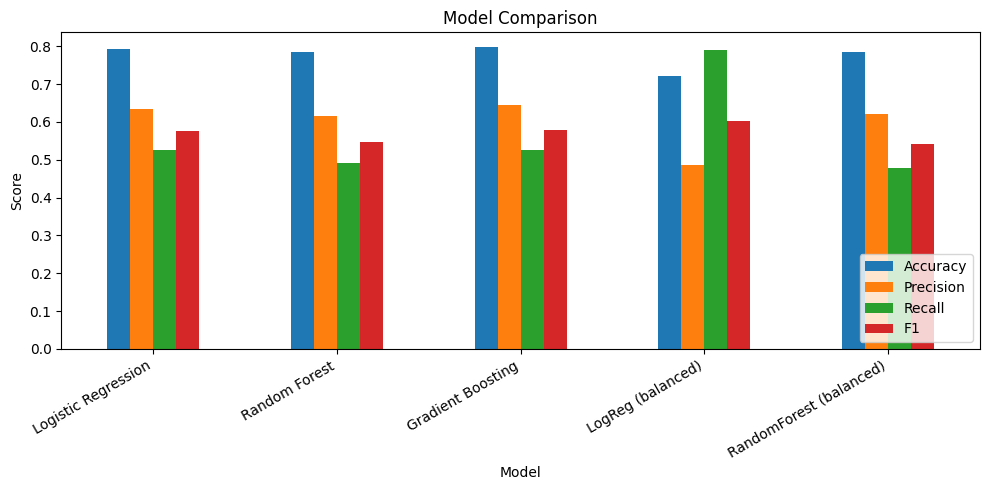

In [20]:
all_results.set_index("Model")[["Accuracy", "Precision", "Recall", "F1"]].plot(kind="bar", figsize=(10, 5))
plt.title("Model Comparison")
plt.ylabel("Score")
plt.xticks(rotation=30, ha="right")
plt.legend(loc="lower right")
plt.tight_layout()
plt.show()

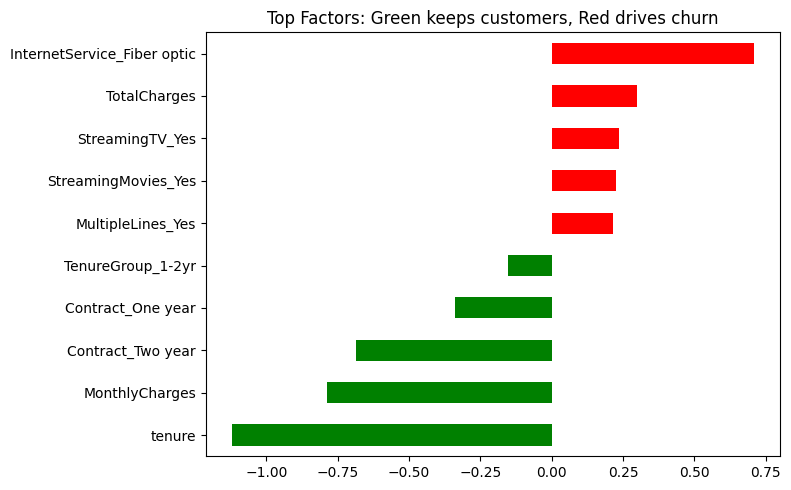

In [21]:
top = pd.concat([coef.head(5), coef.tail(5)])
top.plot(kind="barh", color=["green"]*5 + ["red"]*5, figsize=(8, 5))
plt.title("Top Factors: Green keeps customers, Red drives churn")
plt.tight_layout()
plt.show()

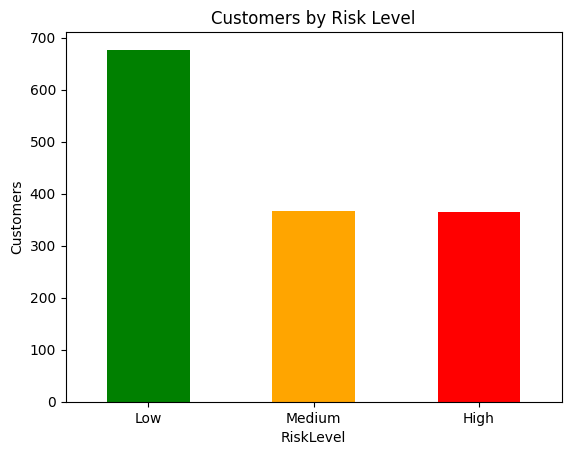

In [22]:
report["RiskLevel"].value_counts().reindex(["Low", "Medium", "High"]).plot(kind="bar", color=["green", "orange", "red"])
plt.title("Customers by Risk Level")
plt.ylabel("Customers")
plt.xticks(rotation=0)
plt.show()

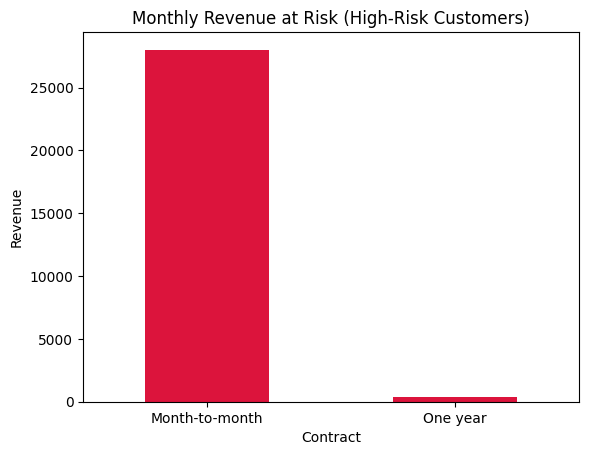

In [23]:
high.groupby("Contract")["MonthlyCharges"].sum().plot(kind="bar", color="crimson")
plt.title("Monthly Revenue at Risk (High-Risk Customers)")
plt.ylabel("Revenue")
plt.xticks(rotation=0)
plt.show()

In [24]:
all_results

,Model,Accuracy,Precision,Recall,F1
0,Logistic Regression,0.793,0.633,0.527,0.575
1,Random Forest,0.784,0.617,0.492,0.548
2,Gradient Boosting,0.797,0.646,0.527,0.580
3,LogReg (balanced),0.721,0.485,0.791,0.602
4,RandomForest (balanced),0.784,0.622,0.479,0.541


## 7. Key Insights
- Overall churn rate is 26.6% (73.4% of customers stayed)
- Month-to-month contracts have the highest churn (42.7%), compared with 11.3% for one year and 2.8% for two year contracts
- Low tenure customers are most at risk
- Top churn drivers: Fiber optic internet service (strongest), TotalCharges, streaming services
- Strongest retention factors: longer tenure, two year and one year contracts
- Best model: Logistic Regression (balanced) with Recall 0.791, Accuracy 0.721, F1 0.602
- Risk segmentation (1,407 test customers): 677 Low, 366 Medium, 364 High risk (25.9%)
- High-risk customers: 364, monthly revenue at risk: 28,400.55

## 8. Recommendations
- Offer discounts for 1 or 2 year contracts
- Run an onboarding programme in the first year
- Contact High-risk customers first
- Review fiber optic service quality and pricing, since these customers churn most

## 9. Conclusion and Future Work
- The model catches about 79% of real churners, so the company can act before customers leave
- Class weighting raised recall from 0.527 to 0.791, at the cost of some accuracy
- Future work: hyperparameter tuning and XGBoost
- Future work: deploy the model as an API or dashboard